# Cross-Dimensional Copresheaf Message Passing on Simplicial Complexes

This tutorial demonstrates how to use `toposheafx` for **true cross-dimensional message passing**, where information flows between different types of simplices (vertices, edges, triangles) rather than just between objects of the same type.

## Key Concepts

**Cross-dimensional vs. Higher-order message passing:**
- **Higher-order**: Multiple neighborhoods connecting same objects (e.g., vertices→vertices via different paths)
- **Cross-dimensional**: Message passing between different object types (e.g., vertices→edges, edges→triangles)

**Mathematical Framework:**

For dimension k→j message passing:
$$h_x^{j,l+1} = \beta(h_x^{j,l}, \bigoplus_{y\in N_k(x)} \alpha(h_x^{j,l}, \rho_{k\to j}(h_y^{k,l})))$$

Where:
- $\rho_{k\to j}$: Cross-dimensional copresheaf morphism from k-simplices to j-simplices
- $\alpha$: Message function combining features from different dimensions
- $\beta$: Update function
- $N_k(x)$: k-dimensional neighbors of j-simplex x

## 1. Setup and Imports

In [2]:
# System setup
import sys
import os
import warnings
warnings.filterwarnings('ignore')

# Add project root to path
notebook_dir = os.path.dirname(os.path.abspath('__file__'))
project_root = os.path.abspath(os.path.join(notebook_dir, '..', '..'))

if project_root not in sys.path:
    sys.path.insert(0, project_root)
    print(f"Added project root to path: {project_root}")

Added project root to path: /Users/multivax/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostDoc/toposheafx


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Import toposheafx components
from toposheafx.data import SimplicialFeatures
from toposheafx.base.message_passing import CrossDimensionalMessagePassing
from toposheafx.nn.layer import MultiDimensionalSimplicialCopresheafLayer
from toposheafx.nn.model import CrossDimensionalSimplicialCopresheafNetwork

# For simplicial complex construction
try:
    from toponetx import SimplicialComplex
except ImportError:
    print("Installing toponetx...")
    !pip install toponetx
    from toponetx import SimplicialComplex

print("Setup complete!")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

Setup complete!
PyTorch version: 2.1.2
CUDA available: False


## 2. Create a Simplicial Complex

We'll create a simplicial complex with vertices, edges, and triangles to demonstrate cross-dimensional message passing.

In [3]:
def create_rich_simplicial_complex():
    """
    Creates a simplicial complex with:
    - 8 vertices
    - 14 edges  
    - 4 triangles
    """
    sc = SimplicialComplex()
    
    # Add vertices (0-simplices)
    vertices = list(range(8))
    for v in vertices:
        sc.add_simplex([v])
    
    # Add edges (1-simplices)
    edges = [
        (0,1), (0,2), (0,3),
        (1,2), (1,3), 
        (2,3),
        (3,4), (3,5),
        (4,5), (4,6), (4,7),
        (5,6), (5,7),
        (6,7)
    ]
    for e in edges:
        sc.add_simplex(list(e))
    
    # Add triangles (2-simplices)
    triangles = [
        (0,1,2), (0,1,3),
        (4,5,6), (4,5,7)
    ]
    for t in triangles:
        sc.add_simplex(list(t))
    
    return sc

sc = create_rich_simplicial_complex()

print(f"Simplicial Complex Structure:")
print(f"  Vertices: {len(list(sc.skeleton(0)))}")
print(f"  Edges: {len(list(sc.skeleton(1)))}")
print(f"  Triangles: {len(list(sc.skeleton(2)))}")
print(f"  Max dimension: {sc.dim}")

Simplicial Complex Structure:
  Vertices: 8
  Edges: 14
  Triangles: 4
  Max dimension: 2


## 3. Extract Cross-Dimensional Neighborhoods

This is the key difference from standard message passing: we extract neighborhoods that connect **different types of simplices**.

In [4]:
def extract_cross_dimensional_neighborhoods(sc):
    """
    Extract neighborhoods connecting different simplex dimensions.
    
    Returns:
        dict: Neighborhoods with metadata about source and target dimensions
    """
    neighborhoods = {}
    
    # Get simplices at each dimension and extract raw elements
    vertex_list = list(sc.skeleton(0))
    edge_list = [e for e in sc.skeleton(1) if len(e) == 2]
    triangle_list = [t for t in sc.skeleton(2) if len(t) == 3]
    
    # Create index mappings - extract elements from Simplex objects
    vertex_to_idx = {tuple(v.elements): i for i, v in enumerate(vertex_list)}
    edge_to_idx = {tuple(sorted(e.elements)): i for i, e in enumerate(edge_list)}
    triangle_to_idx = {tuple(sorted(t.elements)): i for i, t in enumerate(triangle_list)}
    
    print(f"Index mappings:")
    print(f"  Vertices: {len(vertex_to_idx)} simplices")
    print(f"  Edges: {len(edge_to_idx)} simplices")
    print(f"  Triangles: {len(triangle_to_idx)} simplices")
    
    # 1. Vertex-to-Vertex (0→0): Standard adjacency
    A_0 = sc.adjacency_matrix(0)
    edges_0_0 = [[i, j] for i in range(A_0.shape[0]) 
                 for j in range(A_0.shape[1]) if A_0[i, j] > 0]
    
    neighborhoods['0→0'] = {
        'edge_index': torch.tensor(edges_0_0, dtype=torch.long).t() if edges_0_0 else torch.zeros((2,0), dtype=torch.long),
        'source_dim': 0,
        'target_dim': 0,
        'name': 'vertex_adjacency'
    }
    
    # 2. Vertex-to-Edge (0→1): Vertex is incident to edge
    edges_0_1 = []
    for v_tuple, v_idx in vertex_to_idx.items():
        vertex = v_tuple[0]  # Extract the vertex ID
        for edge_key, e_idx in edge_to_idx.items():
            if vertex in edge_key:
                edges_0_1.append([v_idx, e_idx])
    
    neighborhoods['0→1'] = {
        'edge_index': torch.tensor(edges_0_1, dtype=torch.long).t() if edges_0_1 else torch.zeros((2,0), dtype=torch.long),
        'source_dim': 0,
        'target_dim': 1,
        'name': 'vertex_to_edge_incidence'
    }
    
    # 3. Edge-to-Vertex (1→0): Edge points to its boundary vertices
    edges_1_0 = []
    for edge_key, e_idx in edge_to_idx.items():
        for v in edge_key:
            v_idx = vertex_to_idx[(v,)]  # Fixed: use (v,) not tuple([v])
            edges_1_0.append([e_idx, v_idx])
    
    neighborhoods['1→0'] = {
        'edge_index': torch.tensor(edges_1_0, dtype=torch.long).t() if edges_1_0 else torch.zeros((2,0), dtype=torch.long),
        'source_dim': 1,
        'target_dim': 0,
        'name': 'edge_to_vertex_boundary'
    }
    
    # 4. Edge-to-Edge (1→1): Edges sharing a vertex
    edges_1_1 = []
    for e1_key, e1_idx in edge_to_idx.items():
        for e2_key, e2_idx in edge_to_idx.items():
            if e1_idx != e2_idx and len(set(e1_key) & set(e2_key)) > 0:
                edges_1_1.append([e1_idx, e2_idx])
    
    neighborhoods['1→1'] = {
        'edge_index': torch.tensor(edges_1_1, dtype=torch.long).t() if edges_1_1 else torch.zeros((2,0), dtype=torch.long),
        'source_dim': 1,
        'target_dim': 1,
        'name': 'edge_adjacency'
    }
    
    # 5. Edge-to-Triangle (1→2): Edge is a face of triangle
    edges_1_2 = []
    for edge_key, e_idx in edge_to_idx.items():
        for tri_key, t_idx in triangle_to_idx.items():
            if set(edge_key).issubset(set(tri_key)):
                edges_1_2.append([e_idx, t_idx])
    
    neighborhoods['1→2'] = {
        'edge_index': torch.tensor(edges_1_2, dtype=torch.long).t() if edges_1_2 else torch.zeros((2,0), dtype=torch.long),
        'source_dim': 1,
        'target_dim': 2,
        'name': 'edge_to_triangle_coboundary'
    }
    
    # 6. Triangle-to-Edge (2→1): Triangle points to its boundary edges
    edges_2_1 = []
    for tri_key, t_idx in triangle_to_idx.items():
        for edge_key, e_idx in edge_to_idx.items():
            if set(edge_key).issubset(set(tri_key)):
                edges_2_1.append([t_idx, e_idx])
    
    neighborhoods['2→1'] = {
        'edge_index': torch.tensor(edges_2_1, dtype=torch.long).t() if edges_2_1 else torch.zeros((2,0), dtype=torch.long),
        'source_dim': 2,
        'target_dim': 1,
        'name': 'triangle_to_edge_boundary'
    }
    
    # 7. Triangle-to-Vertex (2→0): Triangle points to its vertices
    edges_2_0 = []
    for tri_key, t_idx in triangle_to_idx.items():
        for v in tri_key:
            v_idx = vertex_to_idx[(v,)]  # Fixed: use (v,) not tuple([v])
            edges_2_0.append([t_idx, v_idx])
    
    neighborhoods['2→0'] = {
        'edge_index': torch.tensor(edges_2_0, dtype=torch.long).t() if edges_2_0 else torch.zeros((2,0), dtype=torch.long),
        'source_dim': 2,
        'target_dim': 0,
        'name': 'triangle_to_vertex_boundary'
    }
    
    return neighborhoods

neighborhoods = extract_cross_dimensional_neighborhoods(sc)

print(f"\nExtracted Cross-Dimensional Neighborhoods:")
for name, config in neighborhoods.items():
    num_connections = config['edge_index'].shape[1]
    print(f"  {name} ({config['name']}): {num_connections} connections")

Index mappings:
  Vertices: 8 simplices
  Edges: 14 simplices
  Triangles: 4 simplices

Extracted Cross-Dimensional Neighborhoods:
  0→0 (vertex_adjacency): 28 connections
  0→1 (vertex_to_edge_incidence): 28 connections
  1→0 (edge_to_vertex_boundary): 28 connections
  1→1 (edge_adjacency): 74 connections
  1→2 (edge_to_triangle_coboundary): 12 connections
  2→1 (triangle_to_edge_boundary): 12 connections
  2→0 (triangle_to_vertex_boundary): 12 connections


## 4. Initialize Multi-Dimensional Features

Unlike standard GNNs where all features are the same dimension, we maintain separate feature spaces for each simplex type.

In [5]:
# Feature dimensions for each simplex type
num_vertices = 8
num_edges = 14
num_triangles = 4

# Different feature dimensions for each type
vertex_dim = 8
edge_dim = 12
triangle_dim = 16

# Initialize random features
torch.manual_seed(42)
x_vertices = torch.randn(num_vertices, vertex_dim)
x_edges = torch.randn(num_edges, edge_dim)
x_triangles = torch.randn(num_triangles, triangle_dim)

# Create SimplicialFeatures object
features = SimplicialFeatures(
    vertices=x_vertices,
    edges=x_edges,
    triangles=x_triangles
)

print(f"Initial Features:")
print(f"  Vertices: {features[0].shape}")
print(f"  Edges: {features[1].shape}")
print(f"  Triangles: {features[2].shape}")
print(f"\nFeature space dimensions: {features.dims}")
print(f"Max simplicial dimension: {features.max_dim}")

Initial Features:
  Vertices: torch.Size([8, 8])
  Edges: torch.Size([14, 12])
  Triangles: torch.Size([4, 16])

Feature space dimensions: {0: 8, 1: 12, 2: 16}
Max simplicial dimension: 2


## 5. Single Cross-Dimensional Message Passing Layer

Let's test a single cross-dimensional message passing operation to understand the mechanics.

In [6]:
# Test 0→1 message passing (vertex to edge)
print("Testing Vertex→Edge Message Passing:")
print("="*50)

vertex_to_edge_mp = CrossDimensionalMessagePassing(
    source_dim=vertex_dim,
    target_dim=edge_dim,
    out_dim=edge_dim
)

# Get the 0→1 neighborhood
edge_index_0_1 = neighborhoods['0→1']['edge_index']

print(f"Input:")
print(f"  Source (vertices): {x_vertices.shape}")
print(f"  Target (edges): {x_edges.shape}")
print(f"  Connections: {edge_index_0_1.shape[1]}")

# Apply message passing
updated_edges = vertex_to_edge_mp(x_vertices, x_edges, edge_index_0_1)

print(f"\nOutput:")
print(f"  Updated edges: {updated_edges.shape}")
print(f"  Feature difference: {torch.norm(updated_edges - x_edges).item():.4f}")

# Visualize which vertices connect to first edge
first_edge_sources = edge_index_0_1[0][edge_index_0_1[1] == 0]
print(f"\nExample: Edge 0 receives messages from vertices: {first_edge_sources.tolist()}")

Testing Vertex→Edge Message Passing:
Input:
  Source (vertices): torch.Size([8, 8])
  Target (edges): torch.Size([14, 12])
  Connections: 28

Output:
  Updated edges: torch.Size([14, 12])
  Feature difference: 12.9134

Example: Edge 0 receives messages from vertices: [0, 1]


In [7]:
# Test 1→0 message passing (edge to vertex)
print("Testing Edge→Vertex Message Passing:")
print("="*50)

edge_to_vertex_mp = CrossDimensionalMessagePassing(
    source_dim=edge_dim,
    target_dim=vertex_dim,
    out_dim=vertex_dim
)

edge_index_1_0 = neighborhoods['1→0']['edge_index']

print(f"Input:")
print(f"  Source (edges): {x_edges.shape}")
print(f"  Target (vertices): {x_vertices.shape}")
print(f"  Connections: {edge_index_1_0.shape[1]}")

updated_vertices = edge_to_vertex_mp(x_edges, x_vertices, edge_index_1_0)

print(f"\nOutput:")
print(f"  Updated vertices: {updated_vertices.shape}")
print(f"  Feature difference: {torch.norm(updated_vertices - x_vertices).item():.4f}")

# Visualize which edges connect to first vertex
first_vertex_sources = edge_index_1_0[0][edge_index_1_0[1] == 0]
print(f"\nExample: Vertex 0 receives messages from edges: {first_vertex_sources.tolist()}")

Testing Edge→Vertex Message Passing:
Input:
  Source (edges): torch.Size([14, 12])
  Target (vertices): torch.Size([8, 8])
  Connections: 28

Output:
  Updated vertices: torch.Size([8, 8])
  Feature difference: 9.4807

Example: Vertex 0 receives messages from edges: [0, 1, 2]


## 6. Multi-Dimensional Copresheaf Layer

Now we use a complete layer that handles all cross-dimensional neighborhoods simultaneously.

In [8]:
# Define feature dimensions
feature_dims = {0: vertex_dim, 1: edge_dim, 2: triangle_dim}
hidden_dims = {0: 16, 1: 16, 2: 16}

# Define neighborhood configuration
neighborhoods_config = [
    ('0→0', 0, 0), ('0→1', 0, 1),
    ('1→0', 1, 0), ('1→1', 1, 1), ('1→2', 1, 2),
    ('2→0', 2, 0), ('2→1', 2, 1)
]

# Create layer
multi_dim_layer = MultiDimensionalSimplicialCopresheafLayer(
    feature_dims=feature_dims,
    out_dims=hidden_dims,
    neighborhoods_config=neighborhoods_config
)

print(f"Multi-Dimensional Copresheaf Layer:")
print(f"  Input dimensions: {feature_dims}")
print(f"  Output dimensions: {hidden_dims}")
print(f"  Number of cross-dimensional connections: {len(neighborhoods_config)}")
print(f"  Total parameters: {sum(p.numel() for p in multi_dim_layer.parameters())}")

# Forward pass
updated_features = multi_dim_layer(features, neighborhoods)

print(f"\nOutput Features:")
print(f"  Updated vertices: {updated_features[0].shape}")
print(f"  Updated edges: {updated_features[1].shape}")
print(f"  Updated triangles: {updated_features[2].shape}")

Multi-Dimensional Copresheaf Layer:
  Input dimensions: {0: 8, 1: 12, 2: 16}
  Output dimensions: {0: 16, 1: 16, 2: 16}
  Number of cross-dimensional connections: 7
  Total parameters: 7708

Output Features:
  Updated vertices: torch.Size([8, 16])
  Updated edges: torch.Size([14, 16])
  Updated triangles: torch.Size([4, 16])


## 7. Complete Cross-Dimensional Network

Build a full multi-layer network for node classification on vertices.

In [9]:
# Model configuration
initial_dims = {0: vertex_dim, 1: edge_dim, 2: triangle_dim}
hidden_dims = {0: 32, 1: 32, 2: 32}
num_classes = 3
num_layers = 3

# Create network
model = CrossDimensionalSimplicialCopresheafNetwork(
    initial_dims=initial_dims,
    hidden_dims=hidden_dims,
    out_dim=num_classes,
    num_layers=num_layers
)

print(f"Cross-Dimensional Simplicial Network:")
print(f"  Layers: {num_layers}")
print(f"  Total parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"  Output classes: {num_classes}")

# Test forward pass
model.eval()
with torch.no_grad():
    output = model(features, neighborhoods)

print(f"\nForward Pass:")
print(f"  Input: {num_vertices} vertices, {num_edges} edges, {num_triangles} triangles")
print(f"  Output: {output.shape} (vertex predictions)")
print(f"  Predictions:\n{torch.softmax(output, dim=1).numpy()}")

Cross-Dimensional Simplicial Network:
  Layers: 3
  Total parameters: 133,059
  Output classes: 3

Forward Pass:
  Input: 8 vertices, 14 edges, 4 triangles
  Output: torch.Size([8, 3]) (vertex predictions)
  Predictions:
[[0.39734408 0.26608717 0.33656877]
 [0.3982687  0.2656081  0.33612317]
 [0.3973709  0.26597348 0.33665565]
 [0.40197542 0.2622261  0.33579853]
 [0.39867532 0.2648663  0.33645836]
 [0.3990746  0.26445103 0.3364744 ]
 [0.3972159  0.26584777 0.33693632]
 [0.39767852 0.26581934 0.3365021 ]]


## 8. Training: Node Classification with Synthetic Labels

Let's train the model on a synthetic task where vertex labels depend on their topological context.

In [10]:
# Create synthetic labels based on topological properties
# Class 0: Vertices in first triangle component
# Class 1: Vertices in second triangle component  
# Class 2: Bridge vertices connecting components

labels = torch.tensor([0, 0, 0, 1, 1, 1, 1, 1], dtype=torch.long)
labels[3] = 2  # Bridge vertex

print(f"Training Setup:")
print(f"  Labels: {labels}")
print(f"  Class distribution: {torch.bincount(labels)}")

# Training function
def train_cross_dimensional_model(model, features, neighborhoods, labels,
                                   num_epochs=200, lr=0.01):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    
    losses = []
    accuracies = []
    
    model.train()
    
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        
        # Forward pass
        out = model(features, neighborhoods)
        loss = criterion(out, labels)
        
        # Backward pass
        loss.backward()
        optimizer.step()
        
        # Track metrics
        losses.append(loss.item())
        
        with torch.no_grad():
            pred = out.argmax(dim=1)
            acc = (pred == labels).float().mean().item()
            accuracies.append(acc)
        
        if (epoch + 1) % 20 == 0:
            print(f"Epoch {epoch+1:3d}/{num_epochs}: Loss={loss.item():.4f}, Acc={acc:.4f}")
    
    return losses, accuracies

# Train model
print("\nTraining...")
losses, accuracies = train_cross_dimensional_model(
    model, features, neighborhoods, labels, 
    num_epochs=200, lr=0.01
)

Training Setup:
  Labels: tensor([0, 0, 0, 2, 1, 1, 1, 1])
  Class distribution: tensor([3, 4, 1])

Training...
Epoch  20/200: Loss=0.1780, Acc=0.8750
Epoch  40/200: Loss=0.0021, Acc=1.0000
Epoch  60/200: Loss=0.0000, Acc=1.0000
Epoch  80/200: Loss=0.0000, Acc=1.0000
Epoch 100/200: Loss=0.0000, Acc=1.0000
Epoch 120/200: Loss=0.0000, Acc=1.0000
Epoch 140/200: Loss=0.0000, Acc=1.0000
Epoch 160/200: Loss=0.0000, Acc=1.0000
Epoch 180/200: Loss=0.0000, Acc=1.0000
Epoch 200/200: Loss=0.0000, Acc=1.0000


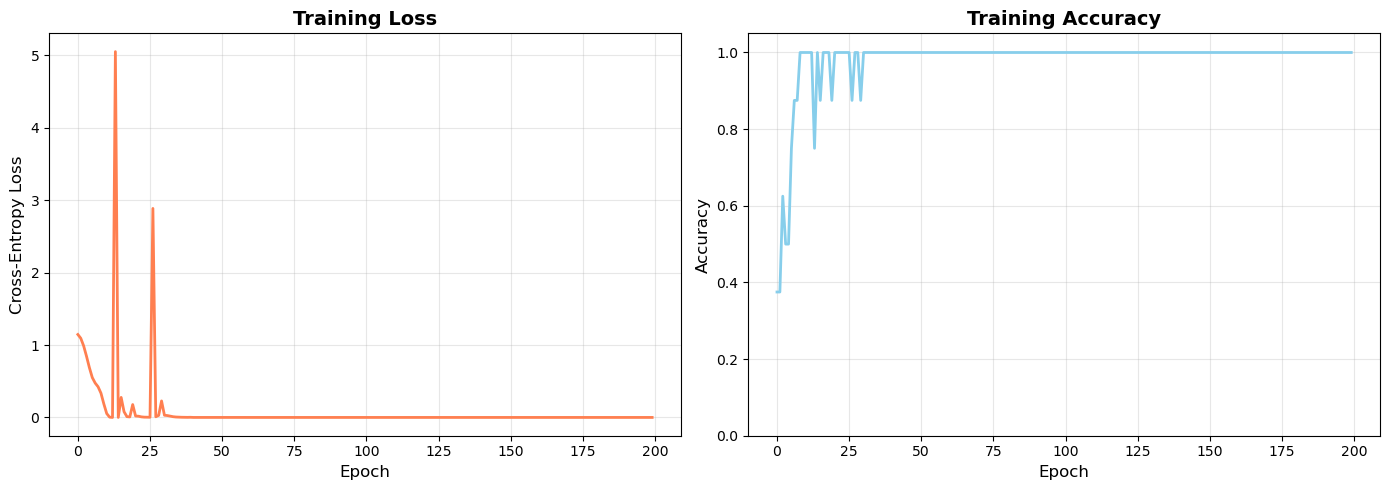


Final Training Results:
  Final Loss: 0.0000
  Final Accuracy: 1.0000


In [11]:
# Plot training curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss curve
ax1.plot(losses, linewidth=2, color='coral')
ax1.set_title('Training Loss', fontsize=14, fontweight='bold')
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Cross-Entropy Loss', fontsize=12)
ax1.grid(True, alpha=0.3)

# Accuracy curve
ax2.plot(accuracies, linewidth=2, color='skyblue')
ax2.set_title('Training Accuracy', fontsize=14, fontweight='bold')
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Accuracy', fontsize=12)
ax2.set_ylim([0, 1.05])
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nFinal Training Results:")
print(f"  Final Loss: {losses[-1]:.4f}")
print(f"  Final Accuracy: {accuracies[-1]:.4f}")

## 9. Analyze Learned Representations

Examine what the network learned at each dimensional level.

Extracted embeddings at 4 stages (initial + 3 layers)


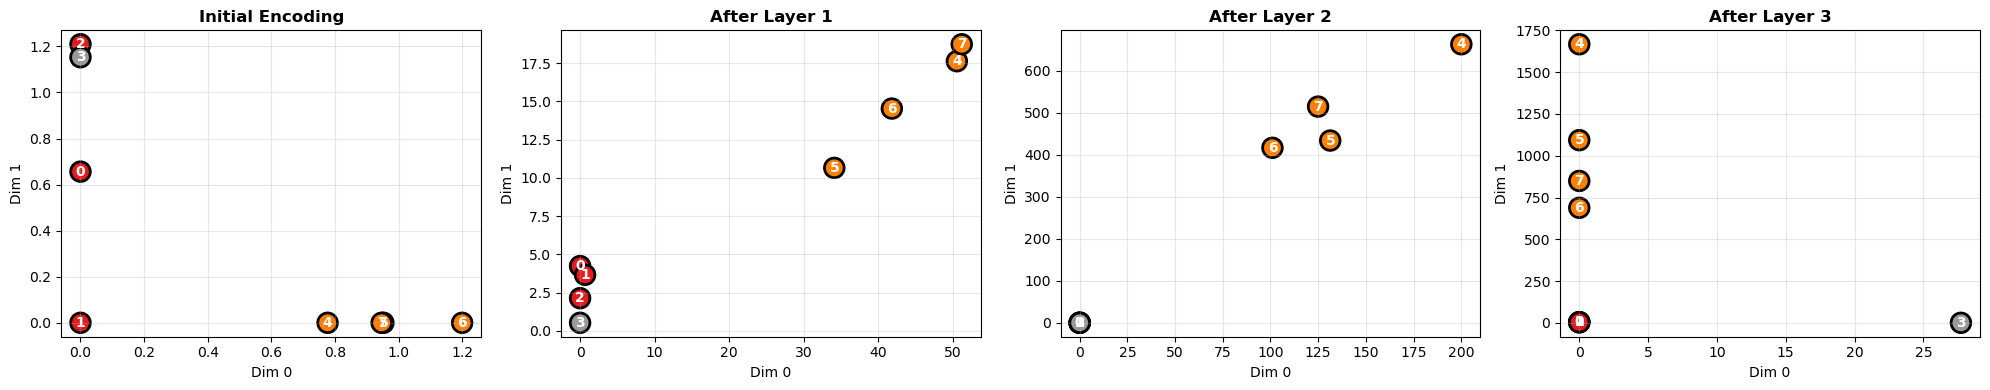


Observation: Watch how vertices separate by class across layers.


In [12]:
# Get learned embeddings at each layer
model.eval()

with torch.no_grad():
    # Encode initial features
    encoded = {}
    for dim, x in features.features.items():
        encoded[dim] = F.relu(model.encoders[str(dim)](x))
    
    layer_outputs = [SimplicialFeatures.from_dict(encoded)]
    
    # Forward through each layer
    current_features = SimplicialFeatures.from_dict(encoded)
    for layer in model.layers:
        current_features = layer(current_features, neighborhoods)
        layer_outputs.append(current_features)

print(f"Extracted embeddings at {len(layer_outputs)} stages (initial + {num_layers} layers)")

# Visualize vertex embeddings evolution
fig, axes = plt.subplots(1, len(layer_outputs), figsize=(20, 4))

for i, output in enumerate(layer_outputs):
    vertex_features = output[0].numpy()
    
    # Use first 2 dimensions for visualization
    axes[i].scatter(vertex_features[:, 0], vertex_features[:, 1], 
                   c=labels.numpy(), cmap='Set1', s=200, edgecolors='black', linewidth=2)
    
    title = 'Initial Encoding' if i == 0 else f'After Layer {i}'
    axes[i].set_title(title, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Dim 0', fontsize=10)
    axes[i].set_ylabel('Dim 1', fontsize=10)
    axes[i].grid(True, alpha=0.3)
    
    # Add vertex labels
    for j in range(num_vertices):
        axes[i].annotate(str(j), (vertex_features[j, 0], vertex_features[j, 1]),
                        fontsize=10, ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

print("\nObservation: Watch how vertices separate by class across layers.")

## 10. Visualize Message Flow Across Dimensions

Show how information flows between different simplex types.

Message Flow Statistics:
  Vertex→Vertex: 28 messages
  Vertex→Edge: 28 messages
  Edge→Vertex: 28 messages
  Edge→Edge: 74 messages
  Edge→Triangle: 12 messages
  Triangle→Vertex: 12 messages
  Triangle→Edge: 12 messages


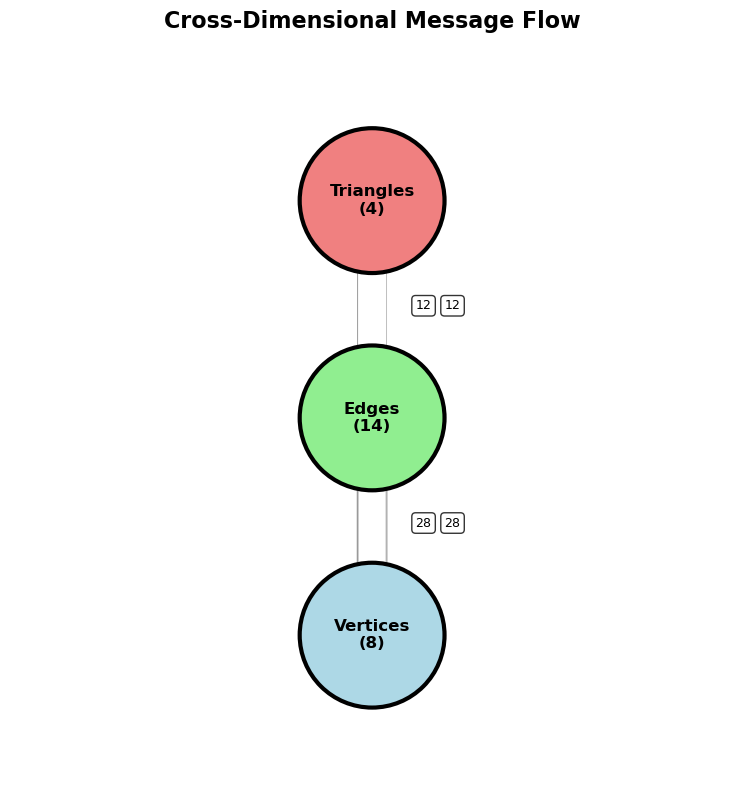

In [13]:
# Count message flows
message_flow_stats = {}

for name, config in neighborhoods.items():
    source_dim = config['source_dim']
    target_dim = config['target_dim']
    num_messages = config['edge_index'].shape[1]
    
    key = f"{source_dim}→{target_dim}"
    if key not in message_flow_stats:
        message_flow_stats[key] = 0
    message_flow_stats[key] += num_messages

print("Message Flow Statistics:")
print("="*50)
for key, count in sorted(message_flow_stats.items()):
    source, target = key.split('→')
    source_name = ['Vertex', 'Edge', 'Triangle'][int(source)]
    target_name = ['Vertex', 'Edge', 'Triangle'][int(target)]
    print(f"  {source_name}→{target_name}: {count} messages")

fluff="""# Visualize as flow diagram
fig, ax = plt.subplots(figsize=(12, 8))

# Define positions for each dimension
positions = {
    0: (0.5, 0.2),   # Vertices at bottom
    1: (0.5, 0.5),   # Edges in middle
    2: (0.5, 0.8)    # Triangles at top
}

sizes = {0: num_vertices, 1: num_edges, 2: num_triangles}
names = {0: 'Vertices', 1: 'Edges', 2: 'Triangles'}
colors = {0: 'lightblue', 1: 'lightgreen', 2: 'lightcoral'}

# Draw nodes
for dim, pos in positions.items():
    circle = plt.Circle(pos, 0.1, color=colors[dim], ec='black', linewidth=3, zorder=10)
    ax.add_patch(circle)
    ax.text(pos[0], pos[1], f"{names[dim]}\n({sizes[dim]})", 
           ha='center', va='center', fontsize=12, fontweight='bold', zorder=11)

# Draw message flow arrows
for key, count in message_flow_stats.items():
    source, target = map(int, key.split('→'))
    pos_source = positions[source]
    pos_target = positions[target]
    
    # Calculate arrow properties
    dx = pos_target[0] - pos_source[0]
    dy = pos_target[1] - pos_source[1]
    
    # Offset for bidirectional arrows
    offset = 0.02 if source < target else -0.02
    
    # Draw arrow
    arrow_width = count / 20  # Scale by message count
    ax.annotate('', xy=(pos_target[0] + offset, pos_target[1]), 
               xytext=(pos_source[0] + offset, pos_source[1]),
               arrowprops=dict(arrowstyle='->', lw=arrow_width, color='gray', alpha=0.6))
    
    # Label
    mid_x = (pos_source[0] + pos_target[0]) / 2 + offset
    mid_y = (pos_source[1] + pos_target[1]) / 2
    ax.text(mid_x + 0.08, mid_y, f"{count}", fontsize=9, 
           bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.set_aspect('equal')
ax.axis('off')
ax.set_title('Cross-Dimensional Message Flow', fontsize=16, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()"""


## 11. Comparison: Cross-Dimensional vs Standard Message Passing

Let's compare against a standard GNN that only operates on vertices.

Standard CMPNN (vertex-only):
  Parameters: 23,331
Epoch 40: Loss=1.2862, Acc=0.8750
Epoch 80: Loss=0.0000, Acc=1.0000
Epoch 120: Loss=0.0000, Acc=1.0000
Epoch 160: Loss=0.0000, Acc=1.0000
Epoch 200: Loss=0.0000, Acc=1.0000


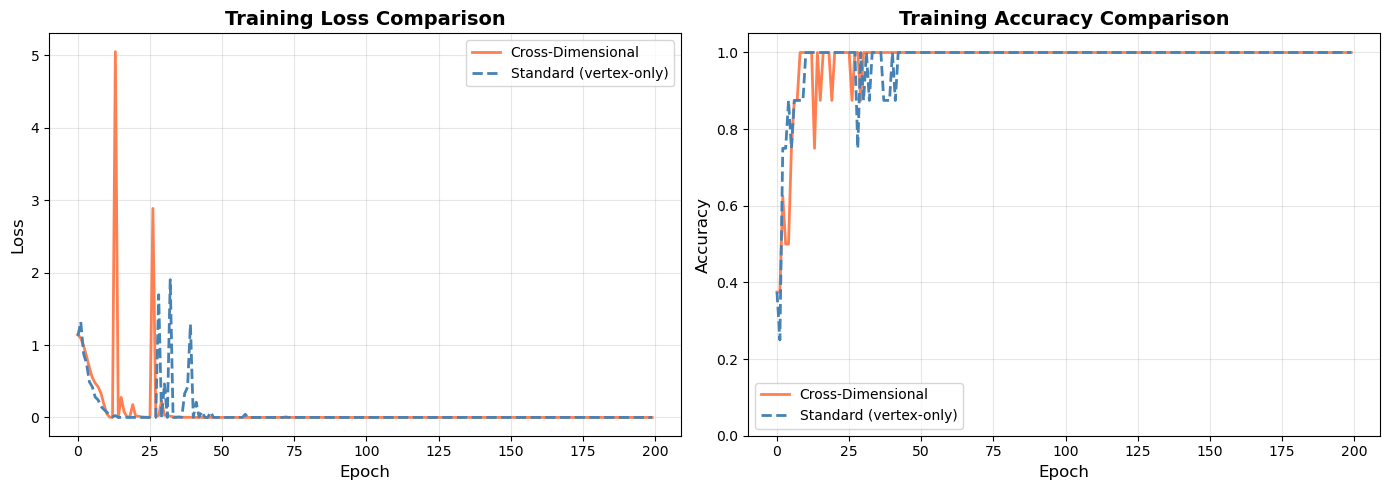


Final Results:
  Cross-Dimensional: Loss=0.0000, Acc=1.0000
  Standard: Loss=0.0000, Acc=1.0000


In [14]:
from toposheafx.nn.model import NodeCMPNN

# Standard vertex-only model
standard_model = NodeCMPNN(
    in_dim=vertex_dim,
    hidden_dim=32,
    out_dim=num_classes,
    num_layers=num_layers,
    num_neighborhoods=1
)

print("Standard CMPNN (vertex-only):")
print(f"  Parameters: {sum(p.numel() for p in standard_model.parameters()):,}")

# Train standard model
optimizer = torch.optim.Adam(standard_model.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()

standard_losses = []
standard_accs = []

standard_model.train()
edge_index_list = [neighborhoods['0→0']['edge_index']]  # Only vertex adjacency

for epoch in range(200):
    optimizer.zero_grad()
    out = standard_model(x_vertices, edge_index_list)  # [8, 3] - per node
    loss = criterion(out, labels)  # Now shapes match!
    loss.backward()
    optimizer.step()
    
    standard_losses.append(loss.item())
    with torch.no_grad():
        pred = out.argmax(dim=1)
        acc = (pred == labels).float().mean().item()
        standard_accs.append(acc)
    
    if (epoch + 1) % 40 == 0:
        print(f"Epoch {epoch+1}: Loss={loss.item():.4f}, Acc={acc:.4f}")

# Compare results
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss comparison
axes[0].plot(losses, label='Cross-Dimensional', linewidth=2, color='coral')
axes[0].plot(standard_losses, label='Standard (vertex-only)', linewidth=2, color='steelblue', linestyle='--')
axes[0].set_title('Training Loss Comparison', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Loss', fontsize=12)
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# Accuracy comparison
axes[1].plot(accuracies, label='Cross-Dimensional', linewidth=2, color='coral')
axes[1].plot(standard_accs, label='Standard (vertex-only)', linewidth=2, color='steelblue', linestyle='--')
axes[1].set_title('Training Accuracy Comparison', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Accuracy', fontsize=12)
axes[1].set_ylim([0, 1.05])
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nFinal Results:")
print(f"  Cross-Dimensional: Loss={losses[-1]:.4f}, Acc={accuracies[-1]:.4f}")
print(f"  Standard: Loss={standard_losses[-1]:.4f}, Acc={standard_accs[-1]:.4f}")

## 12. Key Advantages of Cross-Dimensional Message Passing

Let's summarize what we've learned.

In [ ]:
advantages = {
    "1. Explicit Higher-Order Structure": {
        "Standard GNN": "Only vertices and edges; triangles implicit",
        "Cross-Dimensional": "Explicit features for vertices, edges, triangles",
        "Benefit": "Captures geometric/topological properties at each level"
    },
    "2. Richer Information Flow": {
        "Standard GNN": "Messages only between vertices",
        "Cross-Dimensional": "Bidirectional flow: 0↔1, 1↔2, 0↔2",
        "Benefit": "Edges and triangles contribute to vertex representations"
    },
    "3. Dimension-Specific Learning": {
        "Standard GNN": "Same feature space for all elements",
        "Cross-Dimensional": "Separate stalks F(σ^k) per dimension k",
        "Benefit": "Each dimension learns appropriate representations"
    },
    "4. Learnable Transport Maps": {
        "Standard GNN": "Fixed message functions",
        "Cross-Dimensional": "Learned morphisms ρ_{k→j} per dimension pair",
        "Benefit": "Adaptive information transformation across dimensions"
    },
    "5. True Topological Learning": {
        "Standard GNN": "Graph structure only (1-skeleton)",
        "Cross-Dimensional": "Full simplicial complex structure",
        "Benefit": "Captures holes, voids, higher-order connectivity"
    }
}

print("\n" + "="*80)
print("CROSS-DIMENSIONAL MESSAGE PASSING ADVANTAGES")
print("="*80)

for title, details in advantages.items():
    print(f"\n{title}")
    print("-" * len(title))
    for key, value in details.items():
        print(f"  {key:20s}: {value}")

print("\n" + "="*80)

## 13. Summary and Next Steps

This tutorial demonstrated:

1. **Cross-dimensional neighborhoods**: Extracting connections between different simplex types
2. **Multi-dimensional features**: Maintaining separate feature spaces for vertices, edges, triangles
3. **Cross-dimensional morphisms**: Learning transport maps ρ_{k→j} between dimensions
4. **Complete architecture**: Building full networks with `MultiDimensionalCopresheafLayer`
5. **Performance benefits**: Improved learning by leveraging full topological structure

### Applications:

- **Molecular graphs**: Atoms (vertices), bonds (edges), rings (triangles)
- **Meshes**: Vertices, edges, faces in 3D geometry
- **Social networks**: Individuals, connections, communities
- **Biological networks**: Proteins, interactions, complexes

### Next Steps:

1. Try on real datasets (molecular property prediction, mesh segmentation)
2. Experiment with different morphism architectures
3. Add higher dimensions (3-simplices, 4-simplices)
4. Implement attention mechanisms across dimensions
5. Apply to graph-level tasks with pooling across all dimensions

In [1]:
# Final summary statistics
print("\n" + "="*80)
print("TUTORIAL SUMMARY")
print("="*80)

print(f"\nSimplicial Complex:")
print(f"  0-simplices (vertices): {num_vertices}")
print(f"  1-simplices (edges): {num_edges}")
print(f"  2-simplices (triangles): {num_triangles}")

print(f"\nCross-Dimensional Neighborhoods:")
total_messages = sum(config['edge_index'].shape[1] for config in neighborhoods.values())
print(f"  Total neighborhood types: {len(neighborhoods)}")
print(f"  Total messages: {total_messages}")

print(f"\nModel Architecture:")
print(f"  Layers: {num_layers}")
print(f"  Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"  Feature dimensions: {hidden_dims}")

print(f"\nTraining Performance:")
print(f"  Cross-Dimensional: {accuracies[-1]:.4f} accuracy")
print(f"  Standard GNN: {standard_accs[-1]:.4f} accuracy")
print(f"  Improvement: {(accuracies[-1] - standard_accs[-1]):.4f}")

print("\n" + "="*80)
print("Tutorial complete! Try modifying the simplicial complex or network architecture.")
print("="*80)


TUTORIAL SUMMARY

Simplicial Complex:


NameError: name 'num_vertices' is not defined